In [2]:
import numpy as np

# Create sparse design matrix X with most entries zero
np.random.seed(42)
N, P = 100, 20  # 100 samples, 20 features

# Sparse matrix: 90% zeros
X_sparse = np.random.binomial(1, 0.1, size=(N, P)) * np.random.randn(N, P)

# True sparse coefficients
true_beta = np.zeros(P)
true_beta[[0, 4, 9]] = [2.0, -1.0, 1.5]

# Generate response with noise
y_sparse = X_sparse @ true_beta + np.random.randn(N) * 0.3

import pandas as pd
import matplotlib.pyplot as plt


X_sparse.shape, y_sparse.shape

((100, 20), (100,))

In [5]:
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# Lasso regression pipeline
lasso = Pipeline([
    ('scale', StandardScaler()),
    ('lasso', Lasso(alpha=0.1))  # alpha controls sparsity
])
lasso.fit(X_sparse, y_sparse)
y_pred_lasso = lasso.predict(X_sparse)
mse_lasso = mean_squared_error(y_sparse, y_pred_lasso)
r2_lasso = r2_score(y_sparse, y_pred_lasso)

coef_lasso = lasso.named_steps['lasso'].coef_
zero_lasso = np.sum(np.abs(coef_lasso) < 1e-8)

# Adative Lasso regression pipeline
from jax_model_lib.jax_sklearn_adapter import JaxSparseRegressor

pipe = Pipeline([
    ('scale', StandardScaler()),
    ('jax_model', JaxSparseRegressor())
])
pipe.fit(X_sparse, y_sparse)
y_pred_jax = pipe.predict(X_sparse)
mse_jax = mean_squared_error(y_sparse, y_pred_jax)
r2_jax = r2_score(y_sparse, y_pred_jax)

coef_jax = pipe.named_steps['jax_model'].get_coefficients()
zero_jax = np.sum(np.abs(coef_jax) < 1e-8)


In [6]:
print(f"Lasso Regression     MSE: {mse_lasso:.4f}, R²: {r2_lasso:.4f}")
print(f"JAX Sparse Regressor MSE: {mse_jax:.4f}, R²: {r2_jax:.4f}")

print(f"Lasso shrank to 0:      {zero_lasso} / {len(coef_lasso)}")
print(f"JAX sparse shrank to 0: {zero_jax} / {len(coef_jax)}")

Lasso Regression     MSE: 0.1122, R²: 0.7676
JAX Sparse Regressor MSE: 0.0713, R²: 0.8522
Lasso shrank to 0:      17 / 20
JAX sparse shrank to 0: 2 / 20


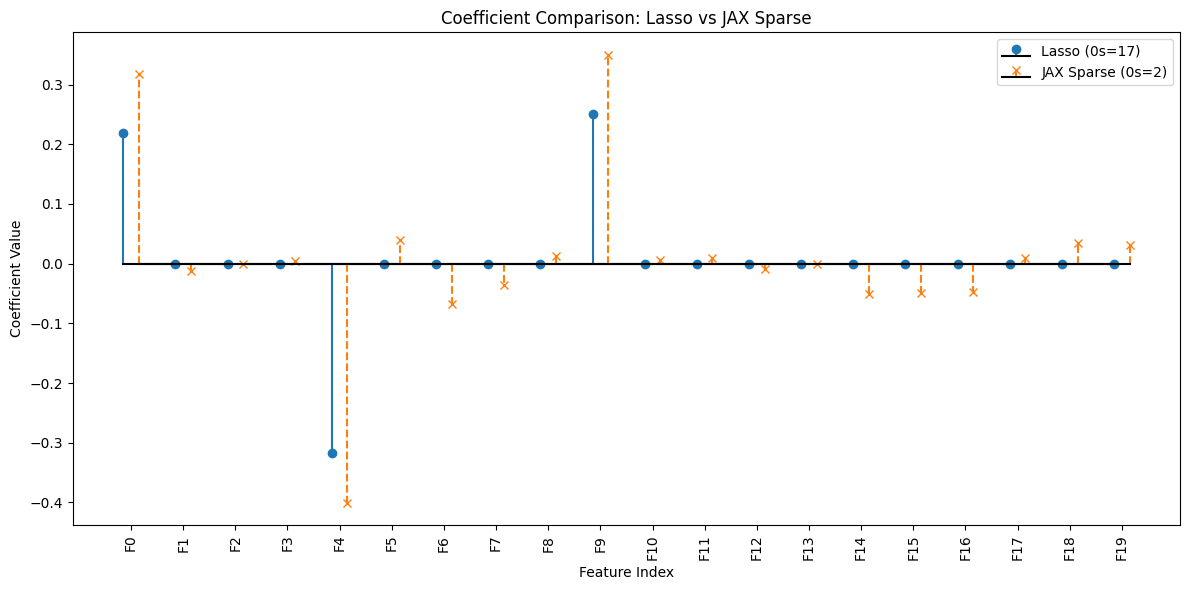

In [7]:
# Plot
x = np.arange(len(coef_lasso))
plt.figure(figsize=(12, 6))
plt.stem(x - 0.15, coef_lasso, linefmt='C0-', markerfmt='C0o', basefmt='k-', label=f'Lasso (0s={zero_lasso})')
plt.stem(x + 0.15, coef_jax, linefmt='C1--', markerfmt='C1x', basefmt='k-', label=f'JAX Sparse (0s={zero_jax})')
plt.xticks(x, [f"F{i}" for i in x], rotation=90)
plt.xlabel("Feature Index")
plt.ylabel("Coefficient Value")
plt.title("Coefficient Comparison: Lasso vs JAX Sparse")
plt.legend()
plt.tight_layout()
plt.show()